## Partie 1 — Explorer et vérifier les données

In [1]:
# 1.Importer les bibliothèques et charger les données

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Charger le fichier Excel
pd.set_option('display.width',1000)
df = pd.read_excel("/Users/osuser/Desktop/Master/apprentissage automatique/transactions_TP2.xlsx")

# Afficher les 5 premières lignes
print(df.head())
print(df.shape)

  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure        canal    appareil             region international resultat_enquete  fraude
0      OP02438    C10278     5396.62             90.0         6.0     11     site_web      mobile     Marrakech-Safi           non    aucune_fraude       0
1      OP00157    C10019      438.41             55.0         2.0     22  application      mobile        Souss-Massa           non    aucune_fraude       0
2      OP01987    C10604     2846.79              NaN         1.0     10    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude       0
3      OP00207    C10330      914.14            127.0         4.0      7  application      mobile  Casablanca-Settat           non    aucune_fraude       0
4      OP00738    C10380      228.23            110.0         4.0      5  application    terminal  Casablanca-Settat           non    aucune_fraude       0
(3045, 12)


In [2]:
#2.Détecter les valeurs manquantes

missing = pd.DataFrame({
   'num_missing' : df.isnull().sum(),
   'pourcentage_missing %' : df.isnull().mean()*100
}).sort_values(by='pourcentage_missing %',ascending=False)

missing

,num_missing,pourcentage_missing %
canal,159,5.221675
anciennete_mois,137,4.499179
appareil,122,4.006568
montant_dh,110,3.612479
region,103,3.382594
nb_ops_24h,53,1.740558
id_operation,0,0.000000
id_client,0,0.000000
heure,0,0.000000
international,0,0.000000


In [3]:
#3.Rechercher et supprimer les doublons

# Compter les doublons
print("Nombre de doublons pour id_operation :",
      df.duplicated(subset="id_operation").sum())

# Supprimer les doublons
df = df.drop_duplicates(
    subset="id_operation",
    keep="first"
)

print("Nombre de lignes restantes :", len(df))

Nombre de doublons pour id_operation : 45
Nombre de lignes restantes : 3000


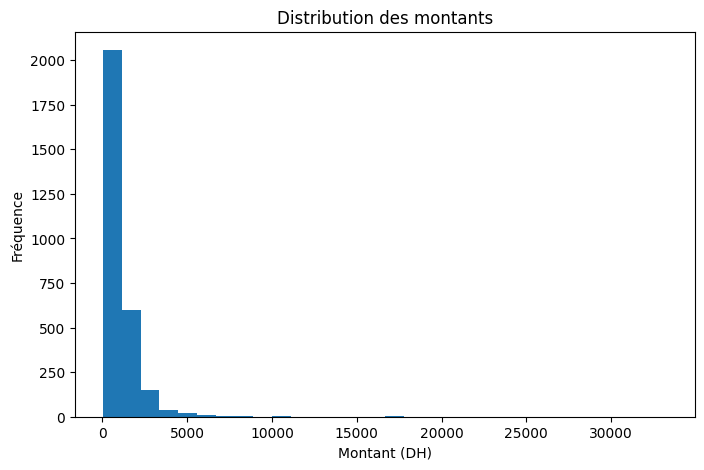

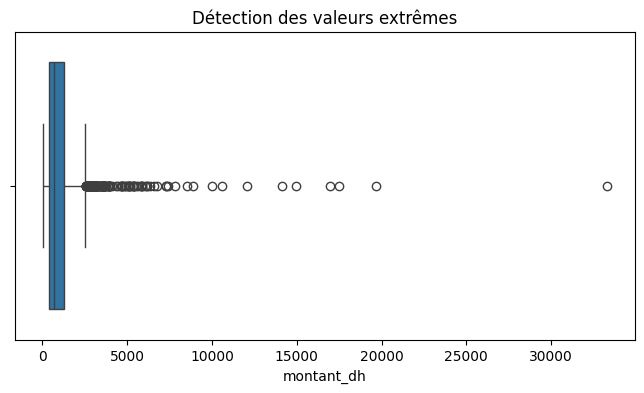

In [4]:
#Détecter les valeurs extrêmes (montant)

# Histogramme
plt.figure(figsize=(8, 5))
plt.hist(df["montant_dh"].dropna(), bins=30)
plt.title("Distribution des montants")
plt.xlabel("Montant (DH)")
plt.ylabel("Fréquence")
plt.show()

# Boxplot
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["montant_dh"])
plt.title("Détection des valeurs extrêmes")
plt.show()

### Faut-il supprimer les valeurs extrêmes ?

Non, pas nécessairement.
Dans le domaine bancaire, une transaction avec un montant élevé peut être parfaitement normale. Il faut donc vérifier si ces valeurs représentent des erreurs ou de véritables opérations avant de décider de les supprimer.

fraude
0    2742
1     258
Name: count, dtype: int64
fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


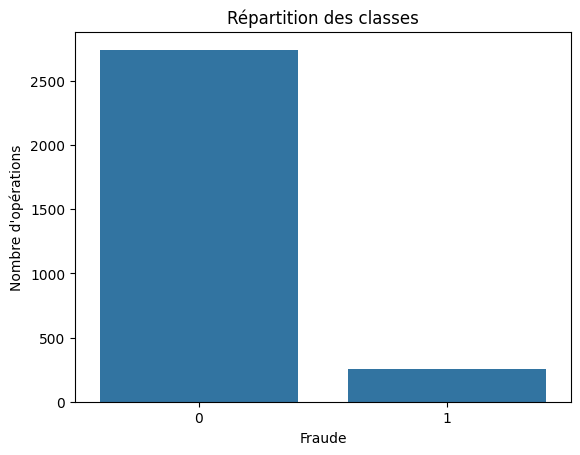

In [5]:
##5.Étudier le déséquilibre des classes

print(df["fraude"].value_counts())

print(df["fraude"].value_counts(normalize=True) * 100)

# Diagramme des classes
sns.countplot(data=df, x="fraude")
plt.title("Répartition des classes")
plt.xlabel("Fraude")
plt.ylabel("Nombre d'opérations")
plt.show()

Interprétation :

Le dataset est déséquilibré, car les opérations normales sont beaucoup plus nombreuses que les opérations frauduleuses.

C'est important parce qu'un modèle pourrait privilégier la classe majoritaire et mal détecter les fraudes. 

### 6.Identifier les colonnes à exclure

ils ne servent à rien :
d_operation	Identifiant de transaction, sans valeur prédictive directe.
id_client	Identifiant du client, pas une variable à transformer dans ce TP.
resultat_enquete	Information connue après l'enquête, donc risque de fuite d'information.

À quel moment connaît-on resultat_enquete ?

On connaît cette information après la réalisation d'une enquête sur la transaction. Elle ne doit donc pas être utilisée pour préparer les variables disponibles au moment de l'opération.

## Partie 2 — Préparer les données sans fuite

In [6]:
##Créer X et y

X = df.drop(columns=[
    "id_operation",
    "id_client",
    "resultat_enquete",
    "fraude"
])

y = df["fraude"]

In [7]:
##8.Séparer les données avec train_test_split

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [8]:
##9.Variables numériques et catégorielles

# Identifier les variables numériques
variables_numeriques = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identifier les variables catégorielles
variables_categorielles = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Variables numériques :")
print(variables_numeriques)

print("\nVariables catégorielles :")
print(variables_categorielles)

Variables numériques :
['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']

Variables catégorielles :
['canal', 'appareil', 'region', 'international']


Pourquoi ne pas traiter les catégories comme des nombres ordinaires ?

Parce que les catégories représentent des modalités et non des quantités.

Par exemple, si on encode :
- application = 1
- téléphone = 2
- site_web = 3
Cela pourrait faire croire à l'algorithme que le site_web est supérieur au téléphone. Cette relation n'a aucun sens.

In [9]:
##10.Pipeline numérique avec StandardScaler

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [10]:
##11.Pipeline catégoriel

from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [11]:
##12.Réunir les deux pipelines avec ColumnTransformer

from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, variables_numeriques),
    ("cat", categorical_pipeline, variables_categorielles)
])

X_train_transformed = preprocessor.fit_transform(X_train)

X_test_transformed = preprocessor.transform(X_test)

X_train_transformed.shape

(2400, 18)

In [12]:
##13.StandardScaler vs RobustScaler

from sklearn.preprocessing import RobustScaler

num_pipeline_robust = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

preprocessor_robust = ColumnTransformer([
    ('num', num_pipeline_robust, variables_numeriques),
    ('cat', categorical_pipeline, variables_categorielles)
])

# 3. Apprendre sur le groupe de référence
X_train_robust = preprocessor_robust.fit_transform(X_train)
# 4. Transformer le groupe de vérification
X_test_robust = preprocessor_robust.transform(X_test)

standard_pipeline = preprocessor.named_transformers_['num']
robust_pipeline = preprocessor_robust.named_transformers_['num']


# Choisir une opération ordinaire et une opération très élevée
montants = pd.DataFrame(
      [X_train[variables_numeriques].median(), X_train[variables_numeriques].median()],
    columns=variables_numeriques
)

# Opération ordinaire : montant médian
montants.loc[0, 'montant_dh'] = X_train['montant_dh'].median()
# Opération très élevée : montant maximal
montants.loc[1, 'montant_dh'] = X_train['montant_dh'].max()

# Appliquer les deux méthodes
resultats = pd.DataFrame({
    'Montant original': montants['montant_dh'],
    'StandardScaler': standard_pipeline.transform(montants)[:, 0],
    'RobustScaler': robust_pipeline.transform(montants)[:, 0]
})

print(resultats)

   Montant original  StandardScaler  RobustScaler
0            710.79       -0.233411      0.000000
1          33281.23       24.299442     39.892755


cela montre que StandarScaler est sensible aux valeures extremes, la moyenne et l'ecart-type sont tirés vers le haut pas les gros montants ce écrase les valeurs.

RobustScaler basé sur la médiane et l'QR, n'est pas influencé par les outliers. il est donc plus adapté pour la détection de fraude, ou les montants exetrême sont fréquents.

### 14. Expliquez ce qui peut mal se passer si la médiane ou les paramètres de normalisation sont calculés sur toutes les lignes, y compris le groupe de vérification.

Si la médiane, la moyenne ou l'écart-type sont calculés sur l'ensemble des données, y compris le groupe de vérification, on crée une fuite de données (data leakage).Le groupe de vérification n'est plus indépendant, car une partie de son information a déjà été utilisée pour construire les transformations. Les performances mesurées deviennent alors trop optimistes et ne reflètent pas la réalité.En production, le modèle devra traiter des données totalement nouvelles, dont il ne connaît pas les paramètres. Il faut donc calculer tous les paramètres (médiane, moyenne, écart-type) uniquement sur le groupe de référence (train) avec fit(), puis appliquer la même transformation au groupe de vérification avec transform().


## Partie 3 — Comparer les méthodes de mise à l’échelle

In [13]:
## 15.Calculer Q1, Q3 et IQR

Q1 = X_train["montant_dh"].quantile(0.25)
Q3 = X_train["montant_dh"].quantile(0.75)

IQR = Q3 - Q1

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)

Q1 = 393.095
Q3 = 1249.8775
IQR = 856.7825


L'IQR mesure la dispersion des 50% des montants les plus centraux. Contrairement à l'écart-type, il n'est pas influencé par les valeurs extrêmes, car il ignore les 25% les plus petits et les 25% les plus grands.

In [14]:
##16.Repérer les extrêmes 


borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

outliers = X_train[
    (X_train["montant_dh"] < borne_inf) |
    (X_train["montant_dh"] > borne_sup)
]

print("Borne inférieure :", borne_inf)
print("Borne supérieure :", borne_sup)
print("Nombre d'outliers :", len(outliers))

Borne inférieure : -892.0787499999999
Borne supérieure : 2535.05125
Nombre d'outliers : 146


Interprétation :

les 146 montants dépassent principalement la borne supérieure. Ils ne sont pas nécessairement des erreurs : certaines transactions peuvent être réellement élevées.
un montant important comme 500 000 DH pourrait être réel : quelqu’un a pu acheter une voiture ou une maison. Vous devez vérifier ; ne commettez pas d’erreur.

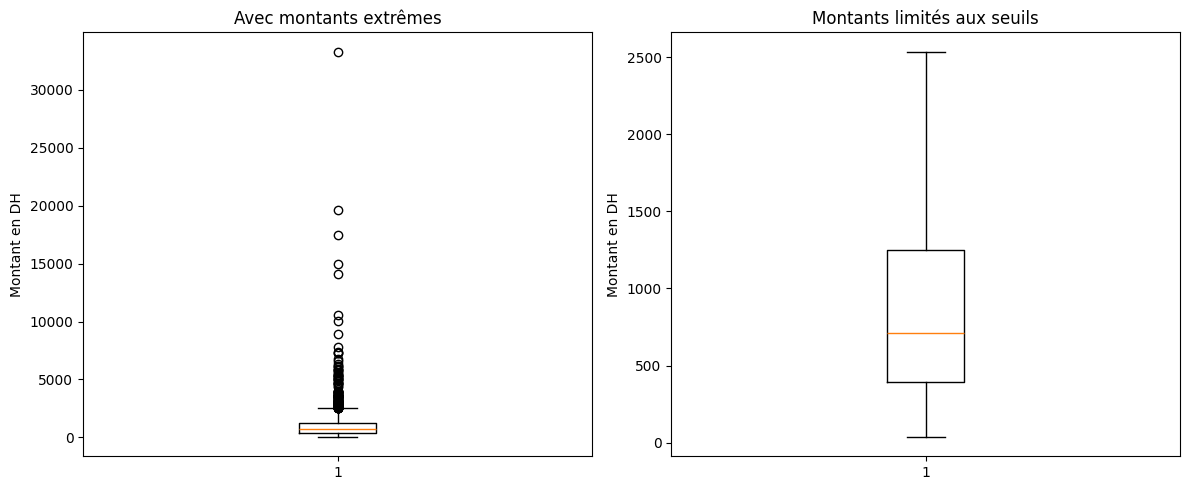

In [18]:
##17.Conserver VS limiter les valeurs extrêmes, 2 Boxplots

import matplotlib.pyplot as plt

plt.close('all')

# 1. Version originale
# 2. Version limitée (Winsorisation / Clipping)
X_train_capped = X_train.copy()
X_train_capped['montant_dh'] = X_train_capped['montant_dh'].clip(lower=borne_inf, upper=borne_sup)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.boxplot(X_train['montant_dh'].dropna().values)
plt.title("Avec montants extrêmes")
plt.ylabel("Montant en DH")

plt.subplot(1, 2, 2)
plt.boxplot(X_train_capped['montant_dh'].dropna().values)
plt.title("Montants limités aux seuils")
plt.ylabel("Montant en DH")

plt.tight_layout()
plt.show()



### Conclusion / Choix :

Le clipping améliore la visualisation et aide le modèle à ne pas être dominé par les très grandes valeurs.Cependant, dans le contexte de la détection de fraude bancaire, ces montants extrêmes ne sont pas forcément des erreurs. Un montant de 33281 DH peut être une transaction légitime, ou au contraire, une fraude réelle.C'est pourquoi, pour ce projet, nous choisissons de conserver les valeurs extrêmes et de ne pas les supprimer ni les modifier définitivement. Le clipping sera utilisé uniquement pour la visualisation. Pour la modélisation, nous privilégierons plutôt un RobustScaler, qui est moins sensible aux outliers que le StandardScaler.

In [30]:
##18.Appliquer les trois méthodes

from sklearn.preprocessing import MinMaxScaler

# IMPORTANT : fit ghir 3la train
minmax = MinMaxScaler().fit(X_train[['montant_dh']])
standard = StandardScaler().fit(X_train[['montant_dh']])
robust = RobustScaler().fit(X_train[['montant_dh']])

# Transform train + test b nafs les paramètres
for name, scaler in [("minmax", minmax), ("standard", standard), ("robust", robust)]:
    X_train[f'montant_{name}'] = scaler.transform(X_train[['montant_dh']])
    X_test[f'montant_{name}'] = scaler.transform(X_test[['montant_dh']])

In [31]:
##19.Tableau de comparaison

from sklearn.preprocessing import MinMaxScaler
exemples = pd.DataFrame({'montant_dh': [100, 500, 2000, 500000]})

exemples['MinMax'] = minmax.transform(exemples[['montant_dh']])
exemples['Standard'] = standard.transform(exemples[['montant_dh']])
exemples['Robust'] = robust.transform(exemples[['montant_dh']])
print(exemples)

   montant_dh     MinMax    Standard      Robust
0         100   0.001913   -0.690077   -0.712888
1         500   0.013945   -0.394055   -0.246025
2        2000   0.059065    0.716026    1.504711
3      500000  15.038842  369.262991  582.749076


### Quelle méthode est la plus perturbée par les valeurs extrêmes ?

Pour les valeurs normales, les trois méthodes donnent des résultats proches. Pour la valeur extrême de 500 000 DH, aucune méthode ne résiste : MinMax sort de [0,1] et donne environ 15, Standard donne environ 369 et Robust donne environ 582.
La méthode la plus perturbée est MinMaxScaler, car elle utilise le minimum et le maximum, qui sont eux-mêmes des outliers. Un seul montant extrême écrase tous les montants normaux vers 0. RobustScaler est le plus stable car il utilise la médiane et l'IQR, qui ne sont pas influencés par les outliers.

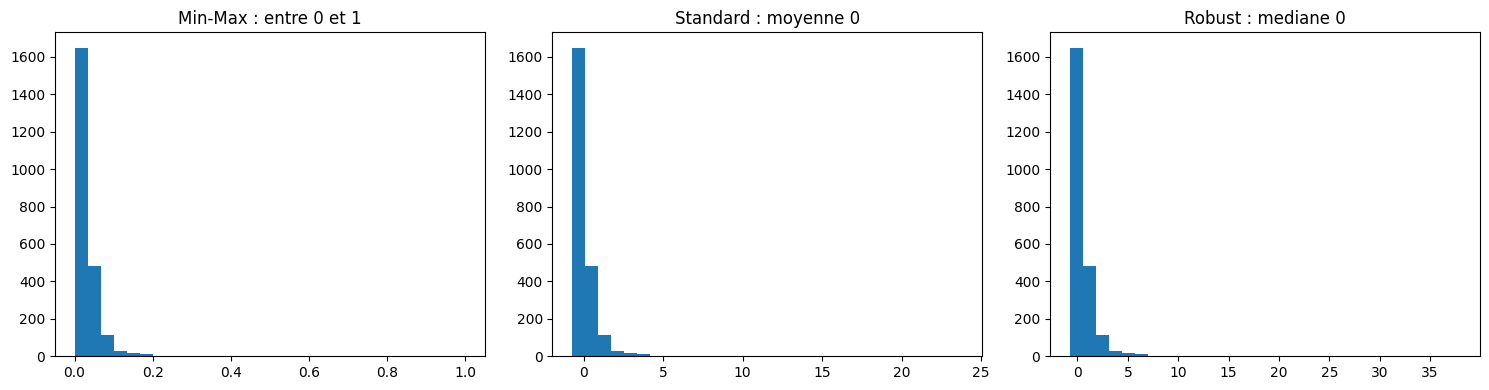

In [32]:
##20.Tracez trois histogrammes du montant transformé

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(X_train['montant_minmax'], bins=30)
plt.title("Min-Max : entre 0 et 1")

plt.subplot(1, 3, 2)
plt.hist(X_train['montant_standard'], bins=30)
plt.title("Standard : moyenne 0")

plt.subplot(1, 3, 3)
plt.hist(X_train['montant_robust'], bins=30)
plt.title("Robust : mediane 0")

plt.tight_layout()
plt.show()

Les trois histogrammes ont la même forme, seule l'échelle change, car la mise à l'échelle est une transformation linéaire. Min-Max utilise le min et le max et ramène les valeurs entre 0 et 1. Z-score utilise la moyenne et l'écart-type et centre les valeurs autour de 0. RobustScaler utilise la médiane et l'IQR et centre les valeurs autour de la médiane. Dans les trois cas, les valeurs normales sont regroupées près de 0 et l'outlier reste isolé très loin.

In [ ]:
##21.MinMaxScaler peut-il dépasser 1

nouveau = pd.DataFrame({'montant_dh': [50000]})
print("Nouveau montant 50000 DH -> MinMax =", minmax.transform(nouveau))
print("Max du train =", X_train['montant_dh'].max())

Nouveau montant 50000 DH -> MinMax = [[1.5028985]]
Max du train = 33281.23


MinMaxScaler applique les paramètres appris sur train. Une nouvelle valeur supérieure au maximum d'apprentissage peut produire une valeur supérieure à 1.

# Partie 4 — Préparer des classes déséquilibrées

In [54]:
##22.Compter les classes dans train

print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

n0 = (y_train == 0).sum()
n1 = (y_train == 1).sum()
print(f"Rapport : {n0} / {n1} = {n0/n1:.2f}")
print(f"Rapport : 1 fraude pour {n0/n1:.2f} non-fraudes")

fraude
0    2194
1     206
Name: count, dtype: int64
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64
Rapport : 2194 / 206 = 10.65
Rapport : 1 fraude pour 10.65 non-fraudes


In [55]:
##23.RandomOverSampler - suréchantillonnage

from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)
X_over, y_over = ros.fit_resample(X_train, y_train)

print("Avant :")
print(y_train.value_counts())
print("Apres OverSampler :")
print(y_over.value_counts())
print(f"Nombre de lignes : {len(X_train)} -> {len(X_over)}")

Avant :
fraude
0    2194
1     206
Name: count, dtype: int64
Apres OverSampler :
fraude
0    2194
1    2194
Name: count, dtype: int64
Nombre de lignes : 2400 -> 4388


### Les nouvelles lignes sont-elles des copies de lignes existantes ?
Oui, les nouvelles lignes sont des copies exactes de lignes existantes de la classe minoritaire. RandomOverSampler ne crée aucune nouvelle information, il duplique simplement des fraudes déjà vues jusqu'à obtenir le même nombre que les non-fraudes. L'avantage est de ne perdre aucune donnée. Le risque est le sur-apprentissage : le modèle apprend par cœur les mêmes fraudes au lieu de généraliser.

In [56]:
##24.RandomUnderSampler - sous-échantillonnage

from imblearn.under_sampling import RandomUnderSampler

# IMPORTANT : on repart du train initial, pas du train déjà sur-échantillonné
rus = RandomUnderSampler(random_state=42)
X_under, y_under = rus.fit_resample(X_train, y_train)

print("Avant :")
print(y_train.value_counts())
print("Apres UnderSampler :")
print(y_under.value_counts())
print(f"Nombre de lignes : {len(X_train)} -> {len(X_under)}")
print(f"Lignes supprimees : {len(X_train) - len(X_under)}")

Avant :
fraude
0    2194
1     206
Name: count, dtype: int64
Apres UnderSampler :
fraude
0    206
1    206
Name: count, dtype: int64
Nombre de lignes : 2400 -> 412
Lignes supprimees : 1988


### Quel est le risque de cette méthode ?
RandomUnderSampler conserve toutes les fraudes et supprime aléatoirement des non-fraudes jusqu'à équilibrer les classes. Le risque est la perte d'information : on jette une grande partie des transactions normales, qui contenaient peut-être des comportements variés. Le modèle devient plus rapide mais moins précis sur la classe majoritaire.

In [57]:
##25.SMOTE sur un petit exemple à 2 variables

from imblearn.over_sampling import SMOTE

# Petit exemple : 2 variables numériques, classe minoritaire = fraude
X_petit = pd.DataFrame({
    'montant_dh': [100, 120, 110, 5000, 5200],
    'heure': [10, 11, 10, 2, 3]
})
y_petit = pd.Series([0, 0, 0, 1, 1])  # 3 non-fraudes, 2 fraudes

print("Avant SMOTE :")
print(X_petit)
print(y_petit.value_counts())

# k_neighbors=1 car on a seulement 2 fraudes
smote = SMOTE(random_state=42, k_neighbors=1)
X_smote, y_smote = smote.fit_resample(X_petit, y_petit)

print("Apres SMOTE :")
print(X_smote)
print(y_smote.value_counts())
print("Nouvelle ligne synthétique :")
print(X_smote.iloc[5:])

Avant SMOTE :
   montant_dh  heure
0         100     10
1         120     11
2         110     10
3        5000      2
4        5200      3
0    3
1    2
Name: count, dtype: int64
Apres SMOTE :
   montant_dh  heure
0         100     10
1         120     11
2         110     10
3        5000      2
4        5200      3
5        5159      2
0    3
1    3
Name: count, dtype: int64
Nouvelle ligne synthétique :
   montant_dh  heure
5        5159      2


SMOTE ne fait pas une simple copie. Il choisit une fraude, puis une de ses voisines de la même classe, et crée un nouveau point sur le segment entre les deux. Par exemple, entre une fraude à 5000 DH à 2h et une fraude à 5200 DH à 3h, SMOTE peut créer une fraude à 5100 DH à 2,5h. Cette valeur est réelle dans l'exemple, elle n'existait pas avant, mais elle est plausible car elle se situe entre deux fraudes réelles. Cela permet d'enrichir la classe minoritaire sans dupliquer.

### 26. Pourquoi faire attention avec OneHotEncoder et SMOTE ?

Il faut faire attention car SMOTE crée des points par interpolation, donc par moyenne. Sur des catégories codées en one-hot, qui doivent valoir 0 ou 1, SMOTE peut créer des valeurs impossibles comme 0,4 ou 0,7 pour "canal_mobile". Ces valeurs n'ont aucun sens.

In [58]:
##27.Tableau récapitulatif

tableau = pd.DataFrame({
    'Classe': ['Non-fraude (0)', 'Fraude (1)', 'Total'],
    'Avant reequilibrage': [ (y_train==0).sum(), (y_train==1).sum(), len(y_train) ],
    'Apres OverSampler': [ (y_over==0).sum(), (y_over==1).sum(), len(y_over) ],
    'Apres UnderSampler': [ (y_under==0).sum(), (y_under==1).sum(), len(y_under) ]
})
print(tableau)
print("Groupe de verification (X_test) - doit rester inchange :")
print(y_test.value_counts())

           Classe  Avant reequilibrage  Apres OverSampler  Apres UnderSampler
0  Non-fraude (0)                 2194               2194                 206
1      Fraude (1)                  206               2194                 206
2           Total                 2400               4388                 412
Groupe de verification (X_test) - doit rester inchange :
fraude
0    548
1     52
Name: count, dtype: int64


###  Le groupe de vérification doit-il changer ?
Avant rééquilibrage, les classes sont déséquilibrées. Après sur-échantillonnage, les deux classes ont le même effectif, mais le total a augmenté car on a dupliqué des fraudes. Après sous-échantillonnage, les deux classes ont le même effectif, mais le total a diminué car on a supprimé des non-fraudes.
Le groupe de vérification ne doit pas changer. Il doit rester avec sa distribution réelle et déséquilibrée, car il sert à évaluer le modèle dans des conditions réelles. Si on rééquilibre aussi le test, on triche et on surestime les performances.


# Partie 5 — Vérifier et enregistrer les données préparées

In [59]:
##28.Construire le pipeline final

from sklearn.compose import ColumnTransformer

numeric_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

categorical_final = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_final = ColumnTransformer([
    ("num", numeric_final, variables_numeriques),
    ("cat", categorical_final, variables_categorielles)
])

In [60]:
##29. fit sur train, transform sur train + test

X_train_prepared = preprocessor_final.fit_transform(X_train)
X_test_prepared = preprocessor_final.transform(X_test)

noms_colonnes = preprocessor_final.get_feature_names_out()

X_train_prepared_df = pd.DataFrame(X_train_prepared, columns=noms_colonnes)
X_test_prepared_df = pd.DataFrame(X_test_prepared, columns=noms_colonnes)

print(f"Train : {X_train_prepared_df.shape} \n Test : {X_test_prepared_df.shape}")
print(f"Valeurs manquantes train : {X_train_prepared_df.isna().sum().sum()}")
print(f"Valeurs manquantes test : {X_test_prepared_df.isna().sum().sum()}")
print(X_train_prepared_df.head(2))

Train : (2400, 18) 
 Test : (600, 18)
Valeurs manquantes train : 0
Valeurs manquantes test : 0
   num__montant_dh  num__anciennete_mois  num__nb_ops_24h  num__heure  cat__canal_agence  cat__canal_application  cat__canal_site_web  cat__canal_telephone  cat__appareil_mobile  cat__appareil_ordinateur  cat__appareil_terminal  cat__region_Autre  cat__region_Casablanca-Settat  cat__region_Draa-Tafilalet  cat__region_Marrakech-Safi  cat__region_Souss-Massa  cat__international_non  cat__international_oui
0        -0.356740             -0.404762              0.0    0.384615                0.0                     1.0                  0.0                   0.0                   1.0                       0.0                     0.0                0.0                            0.0                         1.0                         0.0                      0.0                     0.0                     1.0
1        -0.217748              0.333333              1.0    0.923077                0.0   

In [61]:
##30.Tester une nouvelle catégorie inconnue


# On en prend un ligne, et on remplace 1 ancienne par une nouvelle.
ligne_nouvelle = X_test.iloc[[0]].copy()

print("Categories :", variables_categorielles)

# Nous remplaçons la première colonne catégorielle par une nouvelle valeur.
col_test = variables_categorielles[0]
print(f"Colonne testee : {col_test} - valeur originale : {ligne_nouvelle[col_test].values}")

ligne_nouvelle[col_test] = 'nouvelle_categorie_inconnue'

# Transform 
resultat = preprocessor_final.transform(ligne_nouvelle)
print("Transformation reussie, sans erreur !")
print(f"Forme : {resultat.shape} - doit etre la meme que train : {X_train_prepared.shape[1]} colonnes")

Categories : ['canal', 'appareil', 'region', 'international']
Colonne testee : canal - valeur originale : ['telephone']
Transformation reussie, sans erreur !
Forme : (1, 18) - doit etre la meme que train : 18 colonnes


In [62]:
##31. Enregistrer / Recharger

import joblib

# Enregistrer
joblib.dump(preprocessor_final, 'preprocessor_final.joblib')
print("Enregistre !")

# Recharger
preprocessor_recharge = joblib.load('preprocessor_final.joblib')

# Verifier : meme resultat, sans recalculer
echantillon = X_train.iloc[:3]
res1 = preprocessor_final.transform(echantillon)
res2 = preprocessor_recharge.transform(echantillon)

print("Les deux resultats sont identiques :", np.allclose(res1, res2))
print(res2)

Enregistre !
Les deux resultats sont identiques : True
[[-0.35673954 -0.4047619   0.          0.38461538  0.          1.
   0.          0.          1.          0.          0.          0.
   0.          1.          0.          0.          0.          1.        ]
 [-0.21774757  0.33333333  1.          0.92307692  0.          0.
   1.          0.          0.          1.          0.          0.
   0.          0.          1.          0.          1.          0.        ]
 [-0.28528385 -0.04761905  0.          0.92307692  0.          0.
   1.          0.          1.          0.          0.          0.
   0.          1.          0.          0.          1.          0.        ]]
